In [2]:
import pandas as pd
import numpy as np
import sys
sys.path.insert(0, "..")

What we're checking:
- Whether Iowa and both crops have the expected coverage.

- How many observations have valid yield and soil measurements.

- Whether missing values could affect the comparison.

- Whether yield anomalies contain both positive and negative outcomes.

Do not replace missing yield anomolies or drought values with zero. A missing value is not evidence that no loss or drought occurred.

In [8]:
from src.data_loader import load_master

# Load master dataset.
df = load_master()

# Restrict the initial experiment to Iowa corn and soybeans.
ia_df = df.loc[
    (df['state_alpha'] == 'IA') 
    & (df['crop'].isin(['CORN', 'SOYBEANS']))
    & (df['year'].between(2000, 2025))
].copy()

print('Rows', len(ia_df))
print('Iowa Counties', ia_df['fips'].nunique())
print('Rows per crop:')
print(ia_df.groupby('crop').size())

print('\nMissing values:')
print(
    ia_df[[
        'yield_anomaly_pct',
        'aws_100cm_mm',
        'max_drought_severity',
        'weeks_in_d2_plus',
        'nccpi_crop',
    ]].isna().sum()
)

print('\nYield anomaly summary:')
print(ia_df.groupby('crop')['yield_anomaly_pct'].describe())

Rows 5148
Iowa Counties 99
Rows per crop:
crop
CORN        2574
SOYBEANS    2574
dtype: int64

Missing values:
yield_anomaly_pct       241
aws_100cm_mm              0
max_drought_severity      0
weeks_in_d2_plus          0
nccpi_crop                0
dtype: int64

Yield anomaly summary:
           count      mean        std    min   25%    50%     75%    max
crop                                                                    
CORN      2470.0  0.010684  11.079818 -68.72 -5.27  1.565  7.0175  34.44
SOYBEANS  2437.0  0.007476  11.116406 -49.89 -5.21  1.820  7.0900  33.08


In [37]:
# One soil-storage value per county.
county_soil = (
    ia_df[["fips", "county_name", "aws_100cm_mm", "year"]]
    .dropna(subset=["aws_100cm_mm"])
    .drop_duplicates(subset=["fips"])
    .copy()
)

# Divide counties into three approximately equal-sized groups based on soil water storage capacity.
county_soil["soil_group"] = pd.qcut(
    county_soil["aws_100cm_mm"].rank(method="first"),
    q=3,
    labels=["Low storage", "Medium storage", "High storage"],
)

print('Soil-storage thresholds and group sizes:')
print(
    county_soil.groupby("soil_group", observed=True)
    ["aws_100cm_mm"]
    .agg(["count", "min", "median", "max"])
)

Soil-storage thresholds and group sizes:
                count         min      median         max
soil_group                                               
Low storage        33  154.245463  166.993439  173.808059
Medium storage     33  174.204646  178.999037  182.695271
High storage       33  182.721663  189.884001  205.757359


In [38]:
# Merge the county classification into the crop-year records.
ia_df = ia_df.drop(columns=["soil_group"], errors="ignore")
ia_df = ia_df.merge(
    county_soil[["fips", "soil_group"]],
    on="fips",
    how="left",
    validate="many_to_one",
)

# D2+ exposure; missing drought severity remains unknown.
ia_df["drought_year"] = ia_df["max_drought_severity"].ge(3)


In [39]:

print("Starting rows:", len(ia_df))
print("Rows with yield anomaly:", ia_df["yield_anomaly_pct"].notna().sum())
print("Rows with soil storage:", ia_df["aws_100cm_mm"].notna().sum())
print("Rows with known drought severity:",
      ia_df["max_drought_severity"].notna().sum())

print("Rows with D2+ drought:",
      ia_df["max_drought_severity"].ge(3).sum())

print("\nDrought severity distribution:")
print(ia_df["max_drought_severity"].value_counts(dropna=False).sort_index())

print("\nRows with D2+ drought by crop:")
print(
    ia_df.loc[ia_df["max_drought_severity"].ge(3)]
    .groupby("crop")
    .size()
)


Starting rows: 5148
Rows with yield anomaly: 4907
Rows with soil storage: 5148
Rows with known drought severity: 5148
Rows with D2+ drought: 1702

Drought severity distribution:
max_drought_severity
0.0     825
1.0    1411
2.0    1210
3.0    1080
4.0     586
5.0      36
Name: count, dtype: int64

Rows with D2+ drought by crop:
crop
CORN        799
SOYBEANS    903
dtype: int64


In [ ]:

# Keep only valid outcomes for the initial comparison.
analysis = ia_df.dropna(
    subset=[
        "yield_anomaly_pct",
        "aws_100cm_mm",
        "soil_group",
        "max_drought_severity",
    ]
).copy()


drought = analysis[analysis["drought_year"]].copy()

print("County storage median (mm):", storage_median)
print("Eligible drought observations:", len(drought))
print("Drought observations by crop and soil group:")
print(drought.groupby(["crop", "soil_group"]).size())

County storage median (mm): 178.999036863832
Eligible drought observations: 1598
Drought observations by crop and soil group:
crop      soil_group    
CORN      High storage      118
          Low storage       119
          Medium storage    525
SOYBEANS  High storage      127
          Low storage       125
          Medium storage    584
dtype: int64


How to interpret the results:

- If high-storage counties have a less negative mean yield anomaly, that is consistent with greater soil water storage being associated with better drought resilience.

- If both groups have similar outcomes, your data may show little evidence of a difference.

- If high-storage counties fare worse, investigate sample sizes, drought severity, soil productivity, and other differences before interpreting the result.

In [36]:

summary = (
    drought.groupby(["crop", "soil_group"])["yield_anomaly_pct"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

print(summary)

# Calculate high-storage minus low-storage difference.
means = drought.groupby(
    ["crop", "soil_group"]
)["yield_anomaly_pct"].mean().unstack()

if {"High storage", "Low storage"}.issubset(means.columns):
    means["difference_pp"] = (
        means["High storage"] - means["Low storage"]
    )

print("\nDifference in mean yield anomaly (percentage points):")
print(means.round(2))


                         count  mean  median    std
crop     soil_group                                
CORN     High storage      118 -8.12   -6.37   9.82
         Low storage       119 -6.28   -3.15  18.77
         Medium storage    525 -5.27   -2.77  11.21
SOYBEANS High storage      127 -6.09   -3.66  11.18
         Low storage       125 -7.65   -6.55  17.85
         Medium storage    584 -4.63   -2.16  12.67

Difference in mean yield anomaly (percentage points):
soil_group  High storage  Low storage  Medium storage  difference_pp
crop                                                                
CORN               -8.12        -6.28           -5.27          -1.84
SOYBEANS           -6.09        -7.65           -4.63           1.56


In [40]:

def county_bootstrap_difference(data, crop, n_boot=3000, seed=42):
    """
    Bootstrap the high-minus-low soil-storage difference
    by resampling counties, retaining all rows per county.
    """
    subset = data.loc[
        (data["crop"] == crop)
        & data["soil_group"].isin(["High storage", "Low storage"])
    ].copy()

    # Keep counties with valid yield anomalies.
    subset = subset.dropna(
        subset=["fips", "yield_anomaly_pct", "soil_group"]
    )

    # Each county should belong to exactly one storage group.
    county_groups = (
        subset.groupby("fips")["soil_group"]
        .nunique()
    )
    assert county_groups.max() == 1

    # Store each county's observations.
    county_data = {
        fips: group
        for fips, group in subset.groupby("fips")
    }

    high_ids = [
        fips for fips, group in county_data.items()
        if group["soil_group"].iloc[0] == "High storage"
    ]
    low_ids = [
        fips for fips, group in county_data.items()
        if group["soil_group"].iloc[0] == "Low storage"
    ]

    if not high_ids or not low_ids:
        raise ValueError("Both storage groups need counties.")

    high_mean = subset.loc[
        subset["soil_group"] == "High storage",
        "yield_anomaly_pct"
    ].mean()

    low_mean = subset.loc[
        subset["soil_group"] == "Low storage",
        "yield_anomaly_pct"
    ].mean()

    observed = high_mean - low_mean

    rng = np.random.default_rng(seed)
    estimates = []

    for _ in range(n_boot):
        # Resample counties with replacement within each group.
        sampled_high = rng.choice(
            high_ids, size=len(high_ids), replace=True
        )
        sampled_low = rng.choice(
            low_ids, size=len(low_ids), replace=True
        )

        high_values = pd.concat(
            [county_data[c]["yield_anomaly_pct"]
             for c in sampled_high],
            ignore_index=True,
        )
        low_values = pd.concat(
            [county_data[c]["yield_anomaly_pct"]
             for c in sampled_low],
            ignore_index=True,
        )

        estimates.append(high_values.mean() - low_values.mean())

    lower, upper = np.percentile(estimates, [2.5, 97.5])

    return {
        "crop": crop,
        "high_mean": high_mean,
        "low_mean": low_mean,
        "difference_pp": observed,
        "ci_lower": lower,
        "ci_upper": upper,
        "n_high_counties": len(high_ids),
        "n_low_counties": len(low_ids),
    }


for crop in ["CORN", "SOYBEANS"]:
    print(county_bootstrap_difference(drought, crop))


{'crop': 'CORN', 'high_mean': np.float64(-8.118050847457626), 'low_mean': np.float64(-6.277478991596639), 'difference_pp': np.float64(-1.8405718558609871), 'ci_lower': np.float64(-3.747715543719213), 'ci_upper': np.float64(0.06344113186462468), 'n_high_counties': 14, 'n_low_counties': 17}
{'crop': 'SOYBEANS', 'high_mean': np.float64(-6.093700787401576), 'low_mean': np.float64(-7.654400000000002), 'difference_pp': np.float64(1.5606992125984256), 'ci_lower': np.float64(-0.73031791417497), 'ci_upper': np.float64(3.779179420722122), 'n_high_counties': 14, 'n_low_counties': 17}


In [41]:
model_df = ia_df.dropna(
    subset=[
        "yield_anomaly_pct",
        "aws_100cm_mm",
        "nccpi_crop",
        "max_drought_severity",
        "crop",
        "year",
        "fips",
    ]
).copy()

# D2+ means severity 3 or higher on this dataset's scale.
model_df["drought"] = (
    model_df["max_drought_severity"] >= 3
).astype(int)

# Center storage to make the main effects easier to interpret.
model_df["aws_centered"] = (
    model_df["aws_100cm_mm"]
    - model_df["aws_100cm_mm"].mean()
) / model_df["aws_100cm_mm"].std()

print("Model observations:", len(model_df))
print("Unique counties:", model_df["fips"].nunique())
print(model_df.groupby(["crop", "drought"]).size())

Model observations: 4907
Unique counties: 99
crop      drought
CORN      0          1708
          1           762
SOYBEANS  0          1601
          1           836
dtype: int64


In [42]:
import statsmodels.formula.api as smf

model = smf.ols(
    """
    yield_anomaly_pct
    ~ aws_centered * drought
    + nccpi_crop
    + C(crop)
    + C(year)
    """,
    data=model_df,
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["fips"]}
)

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:      yield_anomaly_pct   R-squared:                       0.452
Model:                            OLS   Adj. R-squared:                  0.449
Method:                 Least Squares   F-statistic:                     151.4
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.26e-69
Time:                        16:46:51   Log-Likelihood:                -17296.
No. Observations:                4907   AIC:                         3.465e+04
Df Residuals:                    4876   BIC:                         3.485e+04
Df Model:                          30                                         
Covariance Type:              cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                4.1222 

In [43]:

model_crop_interaction = smf.ols(
    """
    yield_anomaly_pct
    ~ aws_centered * drought * C(crop)
    + nccpi_crop
    + C(year)
    """,
    data=model_df,
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_df["fips"]}
)

print(model_crop_interaction.summary())


                            OLS Regression Results                            
Dep. Variable:      yield_anomaly_pct   R-squared:                       0.453
Model:                            OLS   Adj. R-squared:                  0.449
Method:                 Least Squares   F-statistic:                     150.3
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           2.85e-70
Time:                        16:55:07   Log-Likelihood:                -17292.
No. Observations:                4907   AIC:                         3.465e+04
Df Residuals:                    4873   BIC:                         3.487e+04
Df Model:                          33                                         
Covariance Type:              cluster                                         
                                               coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------

In [44]:

# Extract the terms relevant to the resilience hypothesis.
terms = [
    "aws_centered",
    "drought",
    "aws_centered:drought",
    "nccpi_crop",
]

results = pd.DataFrame({
    "coefficient": model.params,
    "std_error": model.bse,
    "p_value": model.pvalues,
    "ci_lower": model.conf_int()[0],
    "ci_upper": model.conf_int()[1],
})

print(results.loc[terms].round(4))


                      coefficient  std_error  p_value  ci_lower  ci_upper
aws_centered               0.1795     0.1235   0.1461   -0.0625    0.4216
drought                   -4.3182     0.4098   0.0000   -5.1215   -3.5150
aws_centered:drought      -0.2306     0.4135   0.5771   -1.0412    0.5799
nccpi_crop                -1.1822     0.6034   0.0501   -2.3649    0.0005


In [45]:

import numpy as np
import pandas as pd

# Start with Iowa corn and soybeans.
# Keep yield anomalies missing when they are unavailable.
risk_df = ia_df.copy()

risk_df = risk_df.dropna(
    subset=["fips", "crop", "year", "yield_anomaly_pct"]
)

# Define drought exposure using the dataset's severity scale:
# 3 = D2, 4 = D3, 5 = D4.
risk_df["drought_stress"] = (
    risk_df["max_drought_severity"] >= 3
)

# A transparent initial heat definition:
# at least one day at or above 35 C.
# We can refine this with a training-period threshold later.
risk_df["heat_stress"] = (
    risk_df["extreme_heat_days"] >= 1
)

# Combined exposure, preserving unknown values.
known_drought = risk_df["max_drought_severity"].notna()
known_heat = risk_df["extreme_heat_days"].notna()

risk_df["combined_stress"] = np.where(
    known_drought & known_heat,
    risk_df["drought_stress"] | risk_df["heat_stress"],
    np.nan,
)

def summarize_county(group):
    valid_combined = group["combined_stress"].notna()
    stressed = group.loc[group["combined_stress"] == 1]
    
    return pd.Series({
        "n_years": group["yield_anomaly_pct"].count(),
        "mean_anomaly_pct": group["yield_anomaly_pct"].mean(),
        "drought_frequency": (
            group["drought_stress"].mean()
        ),
        "heat_frequency": (
            group["heat_stress"].mean()
        ),
        "combined_stress_frequency": (
            group.loc[valid_combined, "combined_stress"].mean()
            if valid_combined.any() else np.nan
        ),
        "stress_years": len(stressed),
        "stress_mean_anomaly_pct": (
            stressed["yield_anomaly_pct"].mean()
            if len(stressed) else np.nan
        ),
        "aws_100cm_mm": group["aws_100cm_mm"].median(),
    })

county_risk = (
    risk_df.groupby(
        ["fips", "county_name", "state_alpha", "crop"],
        observed=True
    )
    .apply(summarize_county, include_groups=False)
    .reset_index()
)

print(county_risk.head())


    fips       county_name state_alpha      crop  n_years  mean_anomaly_pct  \
0  19001      Adair County          IA      CORN     24.0      7.500000e-03   
1  19001      Adair County          IA  SOYBEANS     24.0      7.401487e-17   
2  19003      Adams County          IA      CORN     20.0      4.500000e-03   
3  19003      Adams County          IA  SOYBEANS     19.0      2.631579e-03   
4  19005  Allamakee County          IA      CORN     26.0      6.153846e-03   

   drought_frequency  heat_frequency  combined_stress_frequency  stress_years  \
0           0.333333        0.666667                   0.708333          17.0   
1           0.416667        0.666667                   0.708333          17.0   
2           0.300000        0.600000                   0.650000          13.0   
3           0.315789        0.631579                   0.631579          12.0   
4           0.230769        0.230769                   0.346154           9.0   

   stress_mean_anomaly_pct  aws_100cm_

In [80]:

#%pip install geopandas

import geopandas as gpd


counties = gpd.read_file("C:\\Users\\baubb\\OneDrive\\Documents\\Hackathon\\DSU-Hackathon-2026-Irish-Spring-Green\\data\\counties.geojson")

counties["fips"] = counties["fips"].astype(str).str.zfill(5)

corn_map = pd.merge(
    county_risk.loc[county_risk["crop"] == "CORN"],
    counties[["fips", "geometry"]],
    on="fips",
    how="left",
    validate="one_to_many",
)

corn_map

# print(corn_map[[
#     "fips", "county_name", "mean_anomaly_pct",
#     "stress_mean_anomaly_pct"
# ]].head())


,fips,county_name,state_alpha,crop,n_years,mean_anomaly_pct,drought_frequency,heat_frequency,combined_stress_frequency,stress_years,stress_mean_anomaly_pct,aws_100cm_mm,geometry
0,19001,Adair County,IA,CORN,24.0,7.500000e-03,0.333333,0.666667,0.708333,17.0,-2.113529,181.112470,"POLYGON ((-94.70063 41.50415, -94.24159 41.503..."
1,19003,Adams County,IA,CORN,20.0,4.500000e-03,0.300000,0.600000,0.650000,13.0,-2.419231,177.608667,"POLYGON ((-94.92759 41.15851, -94.70059 41.158..."
2,19005,Allamakee County,IA,CORN,26.0,6.153846e-03,0.230769,0.230769,0.346154,9.0,-1.341111,170.589367,"POLYGON ((-91.61084 43.50069, -91.49104 43.500..."
3,19007,Appanoose County,IA,CORN,23.0,2.608696e-02,0.391304,0.652174,0.652174,15.0,-1.694000,162.187838,"POLYGON ((-93.0976 40.89845, -92.63909 40.8988..."
4,19009,Audubon County,IA,CORN,26.0,3.846154e-03,0.307692,0.500000,0.500000,13.0,-6.505385,189.507205,"POLYGON ((-95.09286 41.86337, -94.74488 41.862..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,19189,Winnebago County,IA,CORN,26.0,-6.153846e-03,0.192308,0.500000,0.538462,14.0,-2.931429,188.872691,"POLYGON ((-93.97076 43.4996, -93.64853 43.4995..."
95,19191,Winneshiek County,IA,CORN,26.0,-6.153846e-03,0.230769,0.115385,0.269231,7.0,-3.692857,175.534588,"POLYGON ((-92.08098 43.21295, -92.0798 43.5007..."
96,19193,Woodbury County,IA,CORN,26.0,-3.692308e-02,0.384615,0.769231,0.807692,21.0,-0.563333,199.295555,"POLYGON ((-96.49297 42.51728, -96.47695 42.556..."
97,19195,Worth County,IA,CORN,26.0,-5.000000e-03,0.230769,0.384615,0.500000,13.0,-2.995385,173.259626,"POLYGON ((-93.49735 43.49953, -93.22886 43.499..."


In [83]:
import streamlit as st
import geopandas as gpd
import pydeck as pdk

gdf = gpd.GeoDataFrame(
    corn_map,
    geometry="geometry",
    crs="EPSG:4326"
)

# Convert polygons to GeoJSON
geojson = gdf.__geo_interface__

layer = pdk.Layer(
    "GeoJsonLayer",
    data=geojson,
    get_fill_color="[255 * properties.combined_stress_frequency, 100, 0, 180]",
    get_line_color=[40, 40, 40],
    pickable=True,
    stroked=True,
    filled=True,
    extruded=False,
)

view = pdk.ViewState(
    latitude=42.0,
    longitude=-93.5,
    zoom=6,
    pitch=0,
)

st.pydeck_chart(
    pdk.Deck(
        layers=[layer],
        initial_view_state=view,
        tooltip={"text": "{county_name}\nStress frequency: {combined_stress_frequency}"},
    )
)

2026-10-17 17:34:52.832 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 17:34:52.840 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 17:34:52.842 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-17 17:34:52.844 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

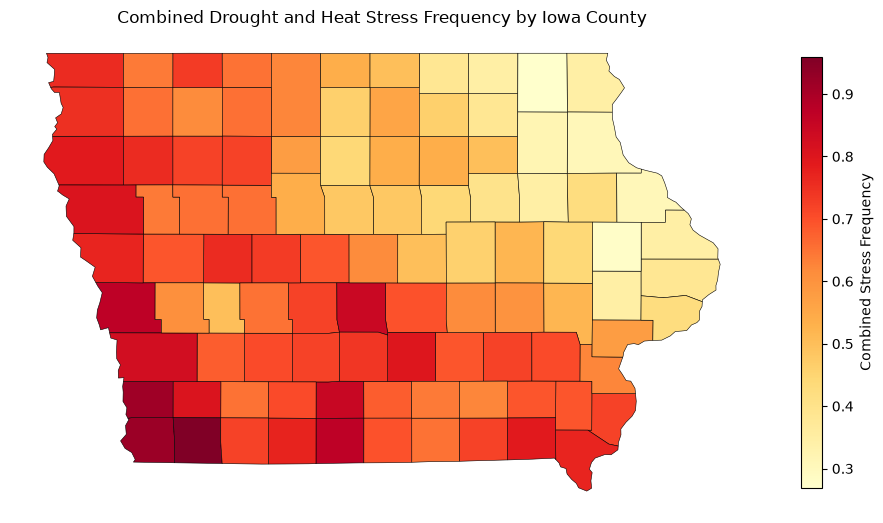

In [86]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Convert your DataFrame to a GeoDataFrame
gdf = gpd.GeoDataFrame(
    corn_map,
    geometry="geometry",
    crs="EPSG:4326"
)

# Plot the counties
gdf.plot(
    column="combined_stress_frequency",
    cmap="YlOrRd",
    legend=True,
    edgecolor="black",
    linewidth=0.4,
    figsize=(12, 8),
    legend_kwds={
        "label": "Combined Stress Frequency",
        "shrink": 0.7
    }
)

plt.title("Combined Drought and Heat Stress Frequency by Iowa County")
plt.axis("off")
plt.show()

In [84]:
%pip install geopandas folium mapclassify

m = gdf.explore(
    column="combined_stress_frequency",
    cmap="YlOrRd",
    tooltip=[
        "county_name",
        "state_alpha",
        "combined_stress_frequency",
        "drought_frequency",
        "heat_frequency"
    ],
    legend=True,
    tiles="CartoDB positron",
    style_kwds={
        "weight": 1,
        "color": "black",
        "fillOpacity": 0.7
    }
)

m

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 2.1/2.1 MB 27.1 MB/s  0:00:00

   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------------------- 1/5 [networkx]
   -------- ------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
c:\Users\baubb\OneDrive\Documents\Hackathon\DSU-Hackathon-2026-Irish-Spring-Green\.venv\Lib\site-packages\geopandas\explore.py:383: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(scale_factor="{r}")
